<a href="https://colab.research.google.com/github/redddddsu/Adaptative-SNN-Based-Triggering/blob/main/Software_Implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importing API/Library


In [ ]:
!pip install snntorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.6/133.6 kB 1.0 MB/s eta 0:00:00


In [ ]:
import torch
import snntorch as snn
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Dataset

In [13]:
import os

save_dir = "/content/drive/MyDrive/TUT_dataset"
os.makedirs(save_dir, exist_ok=True)

!wget -c -O /content/tut_source_events.zip \
"https://zenodo.org/records/401395/files/TUT-rare-sound-events-2017-development.source_data_events.zip?download=1"

!unzip -o /content/tut_source_events.zip -d /content/


Archive:  /content/tut_source_events.zip
   creating: /content/TUT-rare-sound-events-2017-development/
   creating: /content/TUT-rare-sound-events-2017-development/data/
   creating: /content/TUT-rare-sound-events-2017-development/data/source_data/
   creating: /content/TUT-rare-sound-events-2017-development/data/source_data/events/
   creating: /content/TUT-rare-sound-events-2017-development/data/source_data/events/babycry/
  inflating: /content/TUT-rare-sound-events-2017-development/data/source_data/events/babycry/107351.wav  
  inflating: /content/TUT-rare-sound-events-2017-development/data/source_data/events/babycry/107351.yaml  
  inflating: /content/TUT-rare-sound-events-2017-development/data/source_data/events/babycry/144473.wav  
  inflating: /content/TUT-rare-sound-events-2017-development/data/source_data/events/babycry/144473.yaml  
  inflating: /content/TUT-rare-sound-events-2017-development/data/source_data/events/babycry/144474.wav  
  inflating: /content/TUT-rare-sound-ev

In [15]:
import librosa
import numpy as np

babycry_path = "/content/TUT-rare-sound-events-2017-development/data/source_data/events/babycry"

wav_files = sorted(f for f in os.listdir(babycry_path) if f.endswith(".wav"))
audio_path = os.path.join(babycry_path, wav_files[0])
audio, sr = librosa.load(audio_path, sr=None, mono=True)

# Mel Spectrogem

(128, 576)
(128, 576)


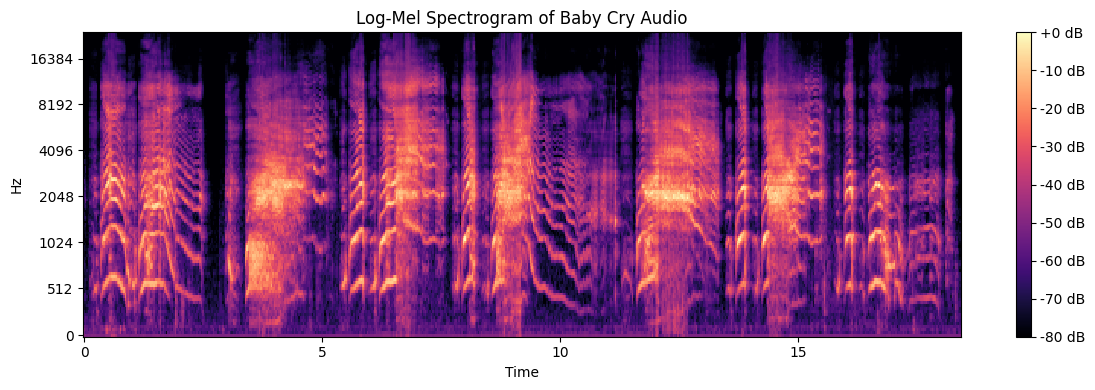

In [16]:
window_sample = round(sr * 0.064)
hops = round(sr * 0.032)

n_mel = 128
n_fft = window_sample

mel = librosa.feature.melspectrogram(y=audio,
    sr=sr,
    n_fft=n_fft,
    win_length=window_sample,
    hop_length=hops,
    n_mels=n_mel,
    power=2)

print(mel.shape)

log_mel = librosa.power_to_db(mel, ref=np.max)
print(log_mel.shape)

plt.figure(figsize=(12, 4))

librosa.display.specshow(log_mel,
    sr=sr,
    hop_length=hops,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Log-Mel Spectrogram of Baby Cry Audio")
plt.tight_layout()
plt.show()

# Label/Time Mapping

In [ ]:
start_time, end_time = annotation["valid_segments"][0]

start_frame = round(start_time / 0.032)
end_frame = round(end_time / 0.032)

print("Start frame:", start_frame)
print("End frame:", end_frame)

Start frame: 6
End frame: 86


# Implementation

In [ ]:
# u_new = (new input)(leak) + u_old
# if the neuron accumalates to over 1 threshold, fire a spike

threshold = 1.0
potential = 0
leak = 0.9
input_test = torch.tensor(0.6)
weight = 1.5

neuron_a = snn.Leaky(beta=leak, threshold=threshold, reset_mechanism="zero")
neuron_b = snn.Leaky(beta=leak, threshold=threshold, reset_mechanism="zero")

mem_a = neuron_a.init_leaky()
mem_b = neuron_b.init_leaky()

for i in range(10):

  spike_a, mem_a = neuron_a(input_test, mem_a)
  input_b = spike_a * weight
  spike_b, mem_b = neuron_b(input_b, mem_b)

  print("Spike A: ", spike_a)
  print("Mem A: ", mem_a)
  print("Spike B: ", spike_b)
  print("Mem B: ", mem_b)


Spike A:  tensor(0.)
Mem A:  tensor(0.6000)
Spike B:  tensor(0.)
Mem B:  tensor(0.)
Spike A:  tensor(1.)
Mem A:  tensor(1.1400)
Spike B:  tensor(1.)
Mem B:  tensor(1.5000)
Spike A:  tensor(0.)
Mem A:  tensor(0.6000)
Spike B:  tensor(0.)
Mem B:  tensor(0.)
Spike A:  tensor(1.)
Mem A:  tensor(1.1400)
Spike B:  tensor(1.)
Mem B:  tensor(1.5000)
Spike A:  tensor(0.)
Mem A:  tensor(0.6000)
Spike B:  tensor(0.)
Mem B:  tensor(0.)
Spike A:  tensor(1.)
Mem A:  tensor(1.1400)
Spike B:  tensor(1.)
Mem B:  tensor(1.5000)
Spike A:  tensor(0.)
Mem A:  tensor(0.6000)
Spike B:  tensor(0.)
Mem B:  tensor(0.)
Spike A:  tensor(1.)
Mem A:  tensor(1.1400)
Spike B:  tensor(1.)
Mem B:  tensor(1.5000)
Spike A:  tensor(0.)
Mem A:  tensor(0.6000)
Spike B:  tensor(0.)
Mem B:  tensor(0.)
Spike A:  tensor(1.)
Mem A:  tensor(1.1400)
Spike B:  tensor(1.)
Mem B:  tensor(1.5000)
